# Frente B, capítulo 1: el espectro de cada época (etapa 6)

**Módulo:** `descriptores/espectro.py` · **Figuras:** `b_espectro_*`

## De qué se trata

El EEG es una mezcla de ritmos que oscilan a distintas frecuencias, y cada estadio de
sueño tiene su propia mezcla. Despierto y con los ojos cerrados domina el ritmo α
(8 a 13 Hz), sobre todo en la zona occipital. A medida que el sueño se profundiza, la
potencia se corre hacia frecuencias bajas, hasta que en N3 dominan las ondas δ
(0,5 a 4 Hz), lentas y de gran amplitud.

Para medir esa mezcla en cada época de 30 s se calcula su **espectro**: cuánta potencia
hay en cada frecuencia. Con el espectro se obtienen los descriptores de este capítulo,
que son la potencia de cada banda, los cocientes entre bandas y la pendiente con que
el espectro cae hacia las frecuencias altas.

## El recorrido de la señal

```
EEG de una época (30 s, 7680 muestras)
   │
   ├─ se multiplica por 29 ventanas DPSS distintas       psd_multitaper()
   ├─ FFT de cada versión y promedio de los 29 espectros
   │
   └─ espectro de la época (µV²/Hz por frecuencia)
          ├─ potencia de cada banda (δ, θ, α, σ, β)        potencia_bandas()
          ├─ potencia relativa y cocientes entre bandas
          └─ pendiente en escala log-log                    pendiente_espectral()
```

Esto se repite para los cuatro canales de EEG (F4, C4, O2 y C3), con 14 descriptores
por canal: 56 en total.

## Entorno y datos

Los resultados de abajo se calcularon con un registro real de la base, SN122 (un
paciente de entrenamiento), y los números del texto son de ese paciente. Si no hay datos descargados, el notebook usa el registro
sintético de `comun/sintetico.py` y las figuras cambian.

Las señales llegan **preprocesadas** por el Frente A (`pipeline.preprocesar`): filtradas
entre 0,2 y 45 Hz con notch en 50 Hz, sin artefacto ocular (Wiener con compuerta) y sin
artefacto cardíaco. El EMG va con un pasa-altos de 10 Hz. La señal cruda queda en
`crudo` para comparar.

In [1]:
# Entorno común a todos los notebooks: se corre desde codigo/ para que DIR_DATOS
# ("data" o $ESTADIOS_DATOS) apunte al mismo lugar que los scripts.
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

# Si el paquete no está instalado con `pip install -e .`, se usa directamente codigo/src.
# Las dependencias (numpy, scipy, pandas, matplotlib, mne) sí tienen que estar
# instaladas en el Python de este kernel.
try:
    import estadios  # noqa: F401
except ModuleNotFoundError:
    sys.path.insert(0, str(Path.cwd() / "src"))
FIGURAS = Path.cwd().parent / "informe" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt

from estadios.comun.config import Config
from estadios.comun.constantes import NOMBRES_ESTADIOS, N_ESTADIOS
from estadios.datos.carga import ids_disponibles

USAR_DATOS_REALES = len(ids_disponibles()) > 0
print("Datos reales" if USAR_DATOS_REALES else "Sin datos descargados: se usan los sintéticos")

Datos reales


In [2]:
# Estilo común de las figuras del Frente B. Cada estadio tiene siempre el mismo color.
COLOR_ESTADIO = dict(zip(NOMBRES_ESTADIOS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
GRIS, TINTA = "#8a8984", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRIS,
    "axes.labelcolor": TINTA,
    "axes.titlesize": 10,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "xtick.color": TINTA,
    "ytick.color": TINTA,
    "lines.linewidth": 1.5,
    "legend.frameon": False,
})


def guardar(fig, nombre):
    """Guarda la figura en informe/figuras/ para incluirla con \\includegraphics."""
    fig.savefig(FIGURAS / f"{nombre}.pdf", bbox_inches="tight")


def por_estadio(ax, valores, estadios, titulo, unidad=""):
    """Diagrama de caja de un descriptor en cada estadio, sin los valores extremos."""
    grupos = [valores[estadios == e] for e in range(N_ESTADIOS)]
    cajas = ax.boxplot(grupos, tick_labels=NOMBRES_ESTADIOS, showfliers=False,
                       patch_artist=True, widths=0.55,
                       medianprops={"color": TINTA, "linewidth": 1.5})
    for caja, nombre in zip(cajas["boxes"], NOMBRES_ESTADIOS):
        caja.set(facecolor=COLOR_ESTADIO[nombre], alpha=0.55, edgecolor=GRIS)
    ax.set(title=titulo, ylabel=unidad)
    ax.grid(axis="x", visible=False)

In [3]:
from estadios.comun.sintetico import preprocesado_sintetico
from estadios.datos.carga import cargar_registro
from estadios.pipeline import preprocesar

cfg = Config().descriptores
if USAR_DATOS_REALES:
    # La señal cruda se guarda para comparar; los descriptores usan la preprocesada.
    # SN122 es el paciente de ejemplo de los textos; si no está, se usa el primero.
    disponibles = ids_disponibles()
    crudo = cargar_registro("SN122" if "SN122" in disponibles else disponibles[0])
    prep = preprocesar(crudo, Config().preprocesamiento)
else:
    prep = preprocesado_sintetico(minutos=120)
    crudo = prep.registro

registro = prep.registro
fs = registro.fs
estadios_tecnicos = registro.estadios
print(f"{registro.id}: {registro.n_epocas} épocas de 30 s ({registro.n_epocas / 120:.1f} h)")
print({n: int((estadios_tecnicos == e).sum()) for e, n in enumerate(NOMBRES_ESTADIOS)})

SN122: 845 épocas de 30 s (7.0 h)
{'W': 66, 'N1': 67, 'N2': 303, 'N3': 288, 'R': 121}


## 1. El problema: el periodograma es muy ruidoso

La forma más directa de estimar el espectro es el **periodograma**: se calcula la FFT de
la época entera y se eleva al cuadrado. El problema es que cada punto del periodograma
es casi una muestra al azar alrededor del valor verdadero, y su error no baja aunque la
época sea más larga. El resultado es un espectro lleno de picos que no significan nada.

Hay dos maneras de reducir ese ruido promediando varios espectros de la misma época.

- **Welch** (visto en clase) corta la época en tramos de 4 s que se solapan a la
  mitad, multiplica cada tramo por una ventana de Hann y promedia sus espectros. Hay
  menos ruido, pero cada tramo es más corto que la época.
- **Multitaper** (técnica no vista en clase) usa la época **entera** 29 veces, cada
  vez multiplicada por una ventana distinta, y promedia los 29 espectros.

La figura compara los tres sobre la misma época de N2.

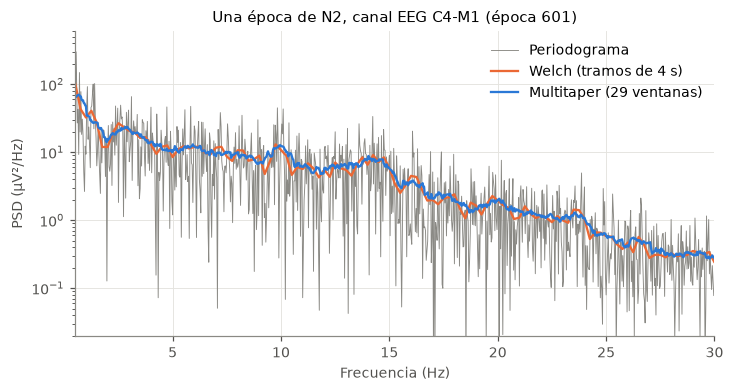

In [4]:
from estadios.comun.constantes import EEG_C4, N2
from estadios.descriptores import espectro
from estadios.preprocesamiento.segmentacion import segmentar

epocas_c4 = segmentar(registro.senales[EEG_C4], fs, registro.n_epocas)
i = int(np.flatnonzero(estadios_tecnicos == N2)[len(np.flatnonzero(estadios_tecnicos == N2)) // 2])
epoca = epocas_c4[i : i + 1]

f_p = np.fft.rfftfreq(epoca.shape[1], 1 / fs)
periodograma = 2 * np.abs(np.fft.rfft(epoca[0] - epoca[0].mean())) ** 2 / (fs * epoca.shape[1])
f_w, psd_w = espectro.psd_welch(epoca, fs)
f_mt, psd_mt = espectro.psd_multitaper(epoca, fs, cfg.multitaper_nw, cfg.multitaper_k)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
desde = f_p >= 0.5  # Sin 0 Hz: ahí el periodograma vale 0 y no tiene logaritmo.
ax.semilogy(f_p[desde], periodograma[desde], color=GRIS, lw=0.6, label="Periodograma")
ax.semilogy(f_w, psd_w[0], color=NARANJA, label="Welch (tramos de 4 s)")
ax.semilogy(f_mt, psd_mt[0], color=AZUL, label="Multitaper (29 ventanas)")
en_rango = periodograma[desde & (f_p <= 30)]
ax.set(xlim=(0.5, 30), ylim=(np.percentile(en_rango, 1), en_rango.max() * 2),
       xlabel="Frecuencia (Hz)", ylabel="PSD (µV²/Hz)",
       title=f"Una época de N2, canal {EEG_C4} (época {i})")
ax.legend()
guardar(fig, "b_espectro_metodos")

El periodograma (gris) salta hasta dos órdenes de magnitud entre frecuencias vecinas. Welch y
multitaper muestran la forma real del espectro: la caída general hacia frecuencias
altas y, en N2, una pequeña elevación en la banda σ (11 a 16 Hz), que es la huella de
los husos de sueño.

## 2. Cómo funciona el multitaper

La clave está en las ventanas. Si se multiplicara la época 29 veces por la **misma**
ventana, los 29 espectros serían idénticos y promediarlos no serviría de nada. Las
ventanas DPSS (o de Slepian) se construyen para que sean **ortogonales entre sí**: cada
una pondera de forma distinta los distintos tramos de la época, de modo que los 29
espectros resultan casi independientes. Al promediar 29 estimaciones independientes, la
varianza baja unas 29 veces.

Dos parámetros definen las ventanas (en `ConfigDescriptores`):

- **NW = 15**, el producto entre la duración (30 s) y la mitad del ancho de banda. Con
  NW = 15 la resolución en frecuencia es de 2 × 15 / 30 = **1 Hz**: dos componentes
  separadas por menos de 1 Hz se ven como una sola.
- **K = 2·NW − 1 = 29**, la cantidad de ventanas. Es el máximo que mantiene concentrada
  la energía de cada ventana dentro de esa banda de 1 Hz.

El precio de promediar es esa resolución de 1 Hz, suficiente para bandas que miden
entre 4 y 17 Hz de ancho. Welch se configuró con tramos de 4 s para que tenga la misma
resolución (el lóbulo principal de una ventana de Hann de 4 s mide 1 Hz), así que la
comparación entre los dos métodos de la hipótesis H1 es justa. Esa comparación se hace
en el notebook 04.

La figura muestra las tres primeras ventanas.

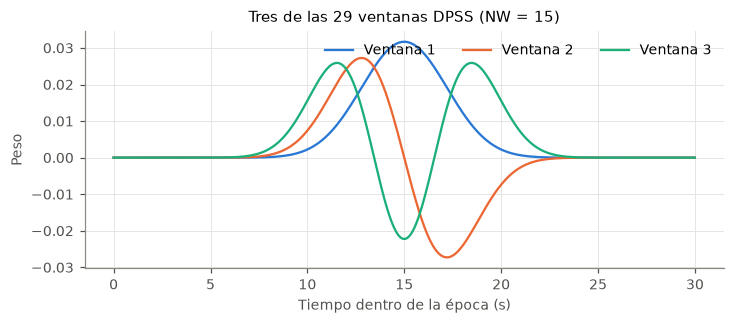

In [5]:
from scipy.signal import windows

ventanas = windows.dpss(epoca.shape[1], cfg.multitaper_nw, 3, norm=2)
t = np.arange(epoca.shape[1]) / fs
fig, ax = plt.subplots(figsize=(7.5, 2.8))
for k, (ventana, color) in enumerate(zip(ventanas, [AZUL, NARANJA, VERDE])):
    ax.plot(t, ventana, color=color, label=f"Ventana {k + 1}")
ax.set(xlabel="Tiempo dentro de la época (s)", ylabel="Peso", title="Tres de las 29 ventanas DPSS (NW = 15)")
ax.legend(ncols=3, loc="upper right")
guardar(fig, "b_espectro_ventanas_dpss")

La primera ventana pesa sobre todo el centro de la época y las siguientes van
oscilando: la tercera, por ejemplo, da importancia a los extremos. Juntas, las 29 usan
toda la época.

## 3. El espectro de cada estadio

Con el multitaper se calcula el espectro de todas las épocas y se promedia por estadio,
según lo que anotaron los técnicos.

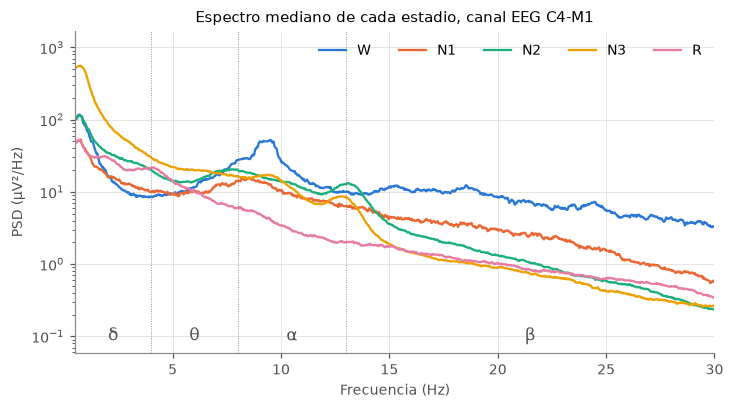

In [6]:
f, psd = espectro.psd_multitaper(epocas_c4, fs, cfg.multitaper_nw, cfg.multitaper_k)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
visible = (f >= 0.5) & (f <= 30)
medianas = {}
for e, nombre in enumerate(NOMBRES_ESTADIOS):
    if (estadios_tecnicos == e).any():
        medianas[nombre] = np.median(psd[estadios_tecnicos == e], axis=0)
        ax.semilogy(f, medianas[nombre], color=COLOR_ESTADIO[nombre], label=nombre)
for banda, (baja, alta) in [("δ", (0.5, 4)), ("θ", (4, 8)), ("α", (8, 13)), ("β", (13, 30))]:
    ax.axvline(alta, color=GRIS, lw=0.6, ls=":")
    ax.text((baja + alta) / 2, 0.04, banda, transform=ax.get_xaxis_transform(), ha="center", color=TINTA, fontsize=11)
minimo = min(m[visible].min() for m in medianas.values())
maximo = max(m[visible].max() for m in medianas.values())
ax.set(xlim=(0.5, 30), ylim=(minimo / 4, maximo * 3), xlabel="Frecuencia (Hz)", ylabel="PSD (µV²/Hz)",
       title=f"Espectro mediano de cada estadio, canal {EEG_C4}")
ax.legend(ncols=5, loc="upper right")
guardar(fig, "b_espectro_por_estadio")

Cada estadio deja su marca. N3 tiene mucha más potencia que el resto por debajo de
4 Hz. W tiene un espectro más plano, con más potencia en α y β. REM y N1 quedan en el
medio y se parecen bastante entre sí, que es justamente el par que más cuesta separar.

## 4. Potencia por banda

`potencia_bandas()` suma el espectro dentro de cada banda (δ, θ, α, σ y β) y lo
multiplica por la separación entre frecuencias: es el área bajo el espectro en esa
banda, en µV². Con eso se arman tres tipos de descriptor por canal.

- **Potencia absoluta**, en escala logarítmica. Varía mucho de un paciente a otro según
  la impedancia de los electrodos, y por eso el clasificador usa más las otras dos.
- **Potencia relativa**: la potencia de la banda dividida por la de 0,5 a 30 Hz. No
  depende de la amplitud general de la señal.
- **Cocientes** δ/θ, δ/β y θ/α, también en logaritmo: suben cuanto más profundo es el
  sueño.

La banda σ se pisa con α y β a propósito: es la banda de los husos, que tienen su
propio capítulo.

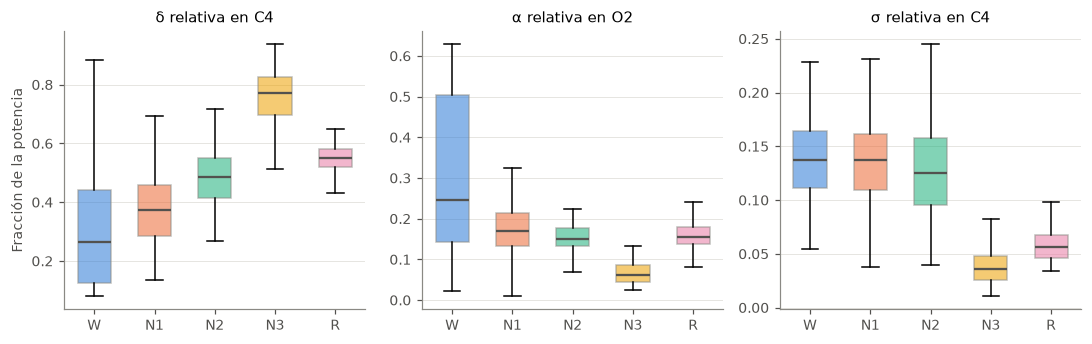

In [7]:
from estadios.comun.constantes import BANDAS_EEG, EEG_O2

f_o2, psd_o2 = espectro.psd_multitaper(segmentar(registro.senales[EEG_O2], fs, registro.n_epocas),
                                       fs, cfg.multitaper_nw, cfg.multitaper_k)


def relativa(f, psd, banda):
    total = espectro.potencia_bandas(f, psd, {"total": espectro.BANDA_TOTAL_HZ})["total"]
    return espectro.potencia_bandas(f, psd, {banda: BANDAS_EEG[banda]})[banda] / total


fig, axs = plt.subplots(1, 3, figsize=(10, 3.2))
por_estadio(axs[0], relativa(f, psd, "delta"), estadios_tecnicos, "δ relativa en C4", "Fracción de la potencia")
por_estadio(axs[1], relativa(f_o2, psd_o2, "alfa"), estadios_tecnicos, "α relativa en O2")
por_estadio(axs[2], relativa(f, psd, "sigma"), estadios_tecnicos, "σ relativa en C4")
fig.tight_layout()
guardar(fig, "b_espectro_bandas")

La potencia δ relativa crece de W a N3 y separa muy bien el sueño profundo. La α en O2
es máxima en W, como se esperaba del ritmo occipital de la vigilia. La σ es la más
sutil de las tres: la diferencia de N2 se ve mejor contando husos uno por uno.

## 5. La pendiente del espectro

Además de los picos de cada ritmo, el espectro del EEG cae de forma regular hacia las
frecuencias altas: en escala log-log es casi una recta. Esa **componente aperiódica**
refleja el equilibrio entre la actividad excitatoria y la inhibitoria del cerebro, y
se vuelve más empinada cuanto más profundo es el sueño (Donoghue et al., 2020).

`pendiente_espectral()` ajusta una recta por mínimos cuadrados entre 1 y 40 Hz, con el
logaritmo de la frecuencia en el eje x y el de la potencia en el eje y. El descriptor
es la pendiente de esa recta.

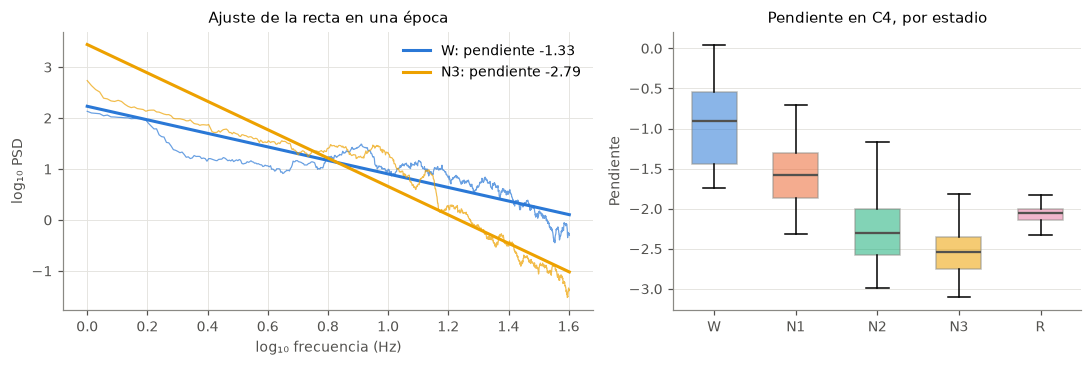

In [8]:
from estadios.comun.constantes import N3, W

rango = (f >= espectro.BANDA_PENDIENTE_HZ[0]) & (f <= espectro.BANDA_PENDIENTE_HZ[1])
pendientes = espectro.pendiente_espectral(f[rango], psd[:, rango])

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), width_ratios=[1.3, 1])
for estadio, nombre in [(W, "W"), (N3, "N3")]:
    indices = np.flatnonzero(estadios_tecnicos == estadio)
    if len(indices) == 0:
        continue
    j = indices[len(indices) // 2]
    log_f, log_p = np.log10(f[rango]), np.log10(psd[j, rango])
    recta = np.polyval(np.polyfit(log_f, log_p, 1), log_f)
    axs[0].plot(log_f, log_p, color=COLOR_ESTADIO[nombre], lw=0.8, alpha=0.7)
    axs[0].plot(log_f, recta, color=COLOR_ESTADIO[nombre], lw=2, label=f"{nombre}: pendiente {pendientes[j]:.2f}")
axs[0].set(xlabel="log₁₀ frecuencia (Hz)", ylabel="log₁₀ PSD", title="Ajuste de la recta en una época")
axs[0].legend()
por_estadio(axs[1], pendientes, estadios_tecnicos, "Pendiente en C4, por estadio", "Pendiente")
fig.tight_layout()
guardar(fig, "b_espectro_pendiente")

La pendiente pasa de valores cercanos a −1 en vigilia a valores más negativos en N2 y
N3. Es un descriptor que no depende de ninguna banda en particular y complementa a la
potencia relativa.

## 6. Lo que sale de este capítulo

`descriptores_espectrales()` hace todo lo anterior para los cuatro canales y devuelve
una matriz con una fila por época y 56 columnas. Los nombres llevan el prefijo
`espectro.` y el canal, por ejemplo `espectro.c4_delta_rel`.

In [9]:
matriz, nombres = espectro.descriptores_espectrales(prep, cfg)
print(f"Matriz: {matriz.shape[0]} épocas × {matriz.shape[1]} descriptores")
print("Los 14 de C4:")
for nombre in nombres:
    if nombre.startswith("espectro.c4"):
        print("  ", nombre)

Matriz: 845 épocas × 56 descriptores
Los 14 de C4:
   espectro.c4_delta_abs
   espectro.c4_delta_rel
   espectro.c4_theta_abs
   espectro.c4_theta_rel
   espectro.c4_alfa_abs
   espectro.c4_alfa_rel
   espectro.c4_sigma_abs
   espectro.c4_sigma_rel
   espectro.c4_beta_abs
   espectro.c4_beta_rel
   espectro.c4_delta_theta
   espectro.c4_delta_beta
   espectro.c4_theta_alfa
   espectro.c4_pendiente
